# Contagion (Mercenary)

Contagion is Parasite's big sibling. It attaches a **60-second** armor-ignoring damage-over-time
effect that ticks for **twice** Parasite's damage and heals the caster for 25% of every tick.
Every cast also rolls a bundled **Curse**, which lowers all five attributes of the target and,
for players, of enemies in an area around the caster. When an infected host dies, a 30-second
copy spreads to up to four of its neighbours.

| | |
|---|---|
| Class | Mercenary |
| Target | Selected enemy (DoT); Curse also splashes around the **caster** |
| Cost | 20 mana (reduced by Concentration) |
| Cooldown | none; no exhaust |
| Landing roll | DoT: none (lands unless the target is immortal). Curse: `chance_base(p, 10, resist)` |
| Duration | DoT 60 s (60 ticks); Curse 120 s; death-spread copies 30 s |
| Damage | true damage, written straight to `a_hp` (no `do_hurt`, no armor) |
| Source | `server/src/driver/skill/mercenary.rs::skill_contagion`; `curse.rs::cast_curse_effect`; tick in `server/src/state/stats.rs`; spread in `server/src/state/death.rs::spread_contagion_on_death` |

---

# Formula

**DoT.** The stored power is the same as Parasite's, with Immunity $I$ and caster race multiplier
$r$:

$$
p' = \left\lfloor r \cdot \text{imm}(p, I) \right\rfloor
\qquad
\text{tick} = 2\max\!\left(1,\ \left\lfloor \tfrac{3p'}{4} \right\rfloor\right)\ \text{HP/s}
\qquad
\text{total} = 60 \cdot \text{tick}
$$

Lifesteal is `tick/4` per second, capped at the caster's max HP.

**Bundled Curse.** After the DoT lands, `cast_curse_effect` rolls against the target's
effective Resist $R$ (after spell penetration). The cast succeeds with probability

$$
P_\text{curse} = \begin{cases}
0 & R > p + \lfloor p/2 \rfloor \\
\dfrac{\operatorname{clamp}(\lfloor 10p / R \rfloor,\ 0,\ 18) + 1}{20} & \text{otherwise}
\end{cases}
$$

On success, `spell_curse` receives the **raw** skill and applies immunity and race itself, so
the curse uses the same $p'$ as the DoT:

$$
\Delta\text{attribute} = -\left\lfloor p'/3 \right\rfloor \quad \text{(all five, 120 s)}
$$

Every skill is derived from three attributes divided by 5, so skills drop by roughly
$\tfrac{3}{5}\lfloor p'/3 \rfloor$. That includes the target's Weapon Skill, Resist and Immunity.

For players, the curse also splashes to every enemy in the `skill_aoe_targets` footprint around
the **caster**, sized by the Contagion **base** skill (`skill[..][0]`). Each splash target lands
on $p + \text{rand}(20) > R + \text{rand}(20)$ using the raw $p$. Splash targets get the curse
only, not the DoT.

| Contagion base | Curse splash footprint |
|---|---|
| 1 – 3 | cross of 4, and only enemies attacking the caster |
| 4 – 6 | 3×3 |
| 7 – 9 | 5×5 |
| ≥ 10 | 7×7 |

**Death spread.** As with Parasite, the copy calls `apply_parasitic_dot` with the stored $p'$, so
immunity and race are applied a second time: $p'_\text{spread} = \lfloor r\cdot\text{imm}(p',
I_\text{new})\rfloor$ for 30 s. Spread copies carry no curse.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
DURATION_S = 60
SPREAD_S = 30
CURSE_D20 = 10

# Model

In [2]:
def contagion_power(p, immun=0, race="Mercenary", moon=None):
    return mm.spell_power(p, immun, race, moon)


def contagion_tick(p, immun=0, race="Mercenary"):
    return mm.dot_tick(contagion_power(p, immun, race), "contagion")


def contagion_total(p, immun=0, race="Mercenary"):
    return DURATION_S * contagion_tick(p, immun, race)


def parasite_total(p, immun=0, race="Mercenary"):
    return 24 * mm.dot_tick(contagion_power(p, immun, race), "parasite")


def curse_attrib_penalty(p, immun=0, race="Mercenary"):
    """Attribute penalty of the bundled Curse (`spell_curse(raw p)`)."""
    return mm.idiv(contagion_power(p, immun, race), 3)


def p_curse_primary(p, resist, pen_pct=0):
    return mm.p_chance_base(p, CURSE_D20, mm.effective_resist(resist, pen_pct))


def p_curse_splash(p, resist, pen_pct=0):
    return mm.p_opposed_d20(p, mm.effective_resist(resist, pen_pct))


def spread_power(stored, immun_new=0, race="Mercenary"):
    return mm.spell_power(stored, immun_new, race)

# Validation

The cells below reproduce values from the Rust unit tests:

- `contagion_costs_mana_and_attaches_long_dot`: 50,000 → 30,000 milli-mana (a 20-mana cost) and
  `active == TICKS*60`.
- `spell_curse_lowers_every_attribute_by_a_third_of_power`: power 30 → −10 on every attribute.
- `spell_curse_power_is_reduced_by_target_immunity`: power 30 against immunity 20 → stored power
  20 and −6. The test caster has no race modifier.
- `parasitic_dot_records_caster_power_and_duration`: power 50 against immunity 20 → 40. This is
  the shared `apply_parasitic_dot`.

In [3]:
assert 50_000 - mm.spell_cost(20) * 1000 == 30_000
assert mm.TICKS * DURATION_S == 2160
assert curse_attrib_penalty(30, race="Other") == 10
assert contagion_power(30, immun=20, race="Other") == 20
assert curse_attrib_penalty(30, immun=20, race="Other") == 6
assert contagion_power(50, immun=20, race="Other") == 40

assert contagion_tick(1, race="Other") == 2             # 2 x floor of 1
assert contagion_tick(100, race="Other") == 150
assert p_curse_primary(50, 50) == 11 / 20               # chance 10 -> 11/20
assert p_curse_primary(50, 76) == 0                      # resist > 1.5p always fails
assert p_curse_primary(100, 10) == 19 / 20               # clamp 18 -> 95%
print("Contagion model OK")

Contagion model OK


# Plots

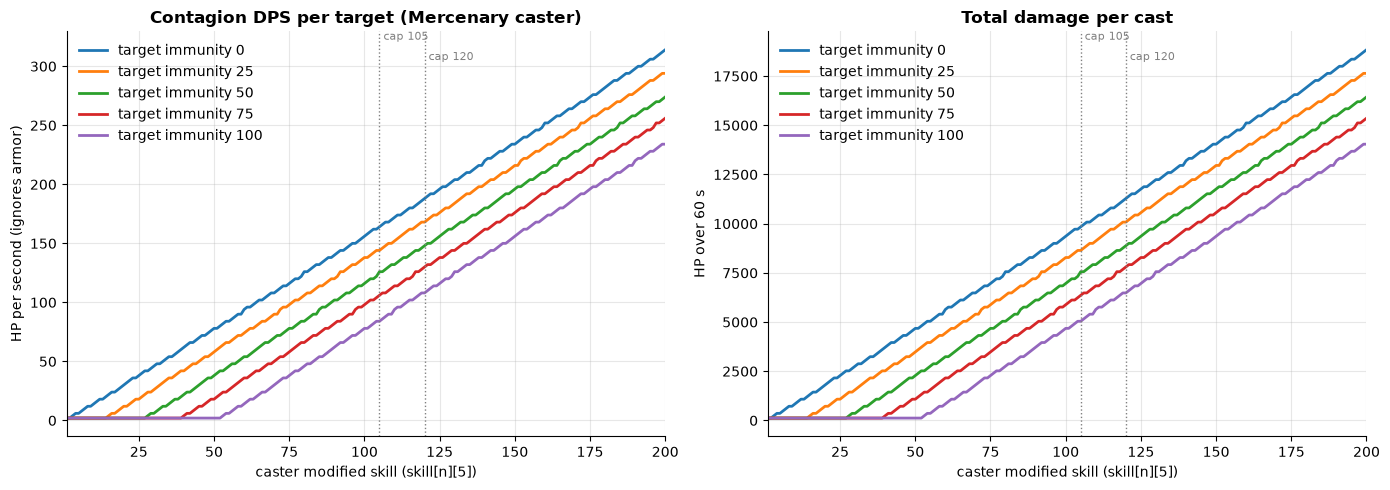

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for immun in mm.IMMUNITY_SWEEP:
    ax.plot(P, contagion_tick(P, immun), label=f"target immunity {immun}")
mm.skill_axis(ax, "HP per second (ignores armor)", "Contagion DPS per target (Mercenary caster)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for immun in mm.IMMUNITY_SWEEP:
    ax.plot(P, contagion_total(P, immun), label=f"target immunity {immun}")
mm.skill_axis(ax, "HP over 60 s", "Total damage per cast")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

The DoT is exactly 2× Parasite's tick and lasts 2.5× as long, so one cast deals 5× a Parasite
cast on the main target for twice the mana. Parasite also infects up to four enemies around the
caster, while Contagion's DoT stays on one target. The right-hand chart below compares them per
point of mana.

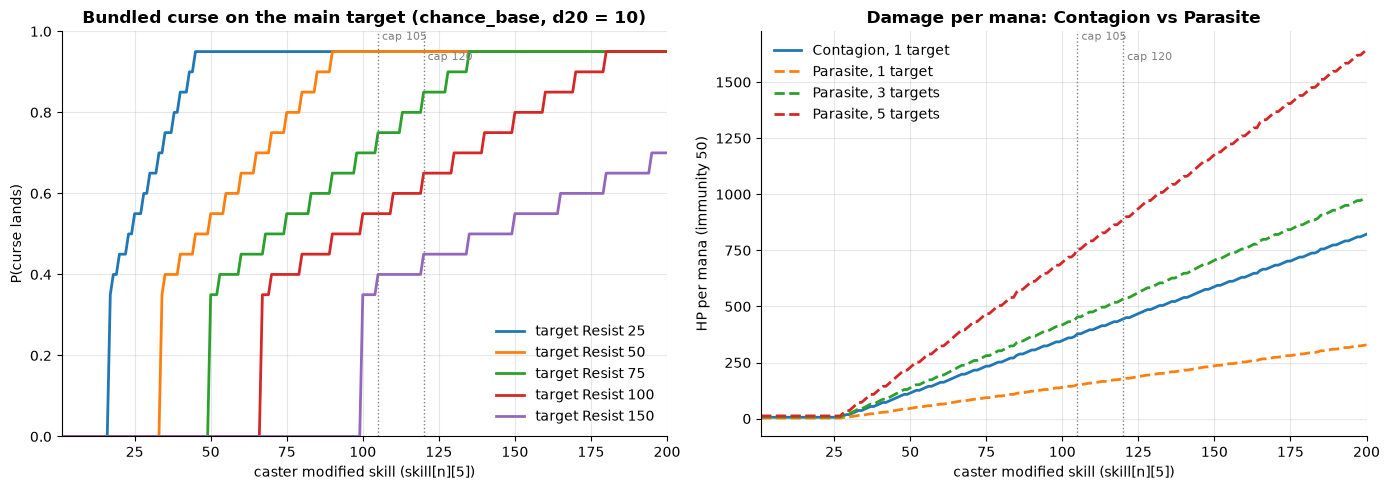

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for resist in mm.RESIST_SWEEP:
    ax.plot(P, p_curse_primary(P, resist), label=f"target Resist {resist}")
mm.skill_axis(ax, "P(curse lands)", "Bundled curse on the main target (chance_base, d20 = 10)")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
ax.plot(P, contagion_total(P, 50) / mm.spell_cost(20), label="Contagion, 1 target")
for n in (1, 3, 5):
    ax.plot(P, n * parasite_total(P, 50) / mm.spell_cost(10), ls="--",
            label=f"Parasite, {n} target{'s' if n > 1 else ''}")
mm.skill_axis(ax, "HP per mana (immunity 50)", "Damage per mana: Contagion vs Parasite")
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

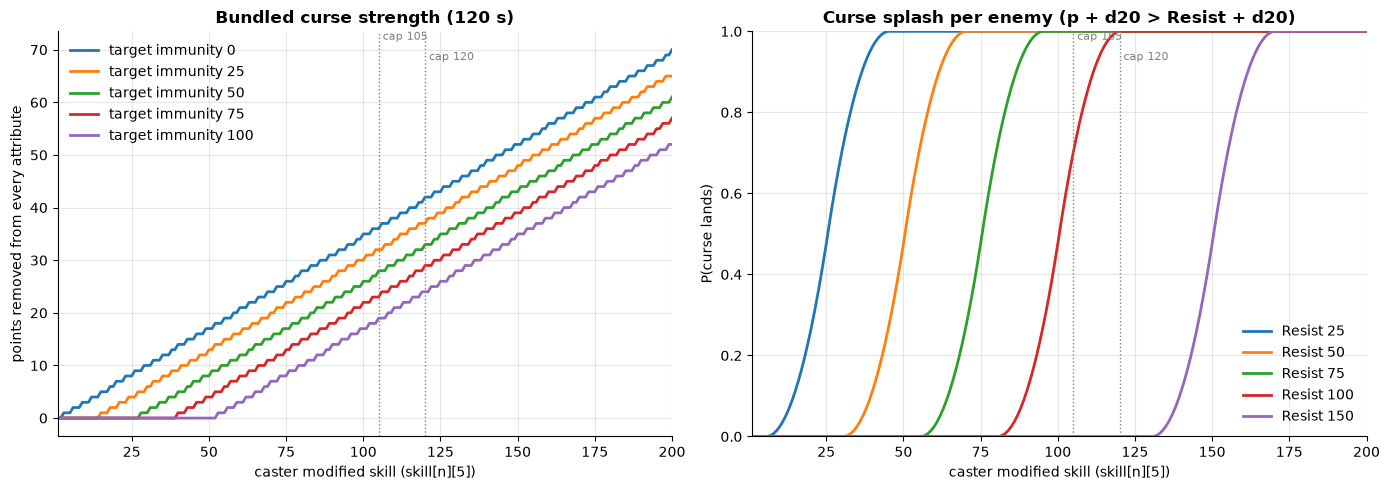

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for immun in mm.IMMUNITY_SWEEP:
    ax.plot(P, curse_attrib_penalty(P, immun), label=f"target immunity {immun}")
mm.skill_axis(ax, "points removed from every attribute", "Bundled curse strength (120 s)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
for resist in mm.RESIST_SWEEP:
    ax.plot(P, p_curse_splash(P, resist), label=f"Resist {resist}")
mm.skill_axis(ax, "P(curse lands)", "Curse splash per enemy (p + d20 > Resist + d20)")
ax.set_ylim(0, 1)
mm.mark_caps(ax)
ax.legend()
plt.tight_layout()

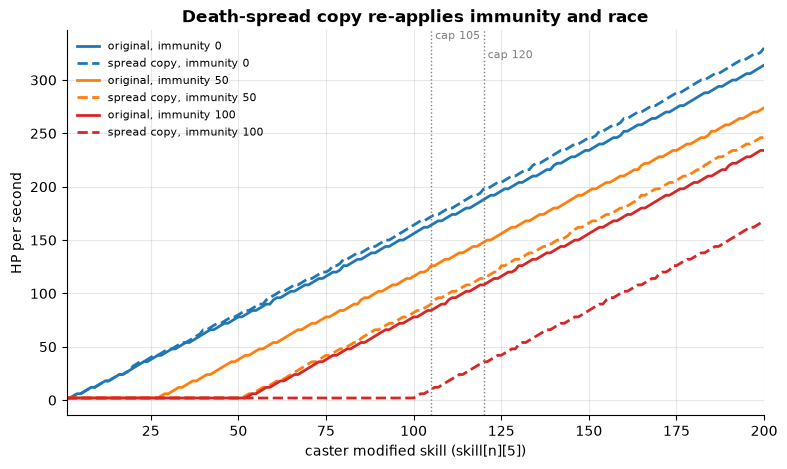

In [7]:
# Death spread: original vs 30 s copy, both hosts with the same immunity.
fig, ax = plt.subplots()
for immun, color in zip((0, 50, 100), ("tab:blue", "tab:orange", "tab:red")):
    stored = contagion_power(P, immun)
    ax.plot(P, mm.dot_tick(stored, "contagion"), color=color, label=f"original, immunity {immun}")
    ax.plot(P, mm.dot_tick(spread_power(stored, immun), "contagion"), color=color, ls="--",
            label=f"spread copy, immunity {immun}")
mm.skill_axis(ax, "HP per second", "Death-spread copy re-applies immunity and race")
mm.mark_caps(ax)
ax.legend(fontsize=8)

# Observations

- **Very strong damage for its mana.** At skill 120 against immunity 50, one 20-mana cast ticks
  148 HP/s, or 8880 HP over 60 s. That is 444 HP per mana, against 178 for a single-target Parasite.
  The caster also heals 37 HP/s. Parasite only matches it per mana when it infects all five targets
  (888 HP per mana). The DoT has no landing roll, no armor check and no exhaust. Only Immunity
  reduces it, and nothing caps it below skill 200.
- **The curse is a coin flip against equal Resist.** `chance_base` with d20 = 10 gives 55% when
  Resist equals the skill, 45% at 1.25× and 35% at 1.5×. Above 1.5× the skill the curse never
  lands. At skill 120 against immunity 50 a landed curse removes 33 from every attribute, about
  20 from every skill, for 120 s. The splash curse uses the opposed d20 roll instead: at skill 120
  it always lands on Resist 100, lands 47.5% of the time on Resist 120 and never on Resist 150.
- **Recasts and spread copies always replace.** `add_spell` keeps a stronger existing spell only
  if it has more than 60 s left. A Contagion never lasts longer than 60 s, so any new copy replaces
  the old one, even a weaker one. A 30 s spread copy from a dying neighbour therefore overwrites a
  fresh full-power cast.
- **Death spread double-dips immunity and race** (same bug as Parasite). At skill 120 against
  immunity 50, the copy ticks 114 HP/s instead of 148. Spread copies can spread again when their
  own host dies.
- **The curse's "AoE" depends on the base skill, not the modified skill.** The splash footprint
  is sized by `skill[SK_CONTAGION][0]`. Gear and buffs that raise the modified skill make the
  curse stronger but never widen the splash.